# MOIA Minimalvarianten: Kurz-Auswertung

Diese Auswertung vergleicht nur die Minimalvarianten mit echten MOIA-Daten:
- __trips (Baseline mit echten Trips)
- __trips__svc_wait_300 (strengere Wartezeit)
- __trips__repo_basic (Basic Repositioning)

Metriken werden aus den standard_eval.csv je Szenario gelesen.

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)

def find_repo_root(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        if (parent / "studies").is_dir():
            return parent
    return start

ROOT = find_repo_root(Path.cwd())
STUDIES = {
    "H1": ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "results",
    "H2": ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "results",
    "UC2": ROOT / "studies" / "uc2_age_based" / "results",
    "UC3": ROOT / "studies" / "uc3_accessibility" / "results",
}
list(STUDIES.keys())

['H1', 'H2', 'UC2', 'UC3']

In [2]:
ROW_NAMES = {
    "service_rate_pct": "served online users [%]",
    "avg_wait_sec": "waiting time",
    "utilization_pct": "% fleet utilization",
    "num_users": "number users",
}

VARIANT_SUFFIXES = {
    "__trips": "trips",
    "__trips__svc_wait_300": "svc_wait_300",
    "__trips__repo_basic": "repo_basic",
}

def load_metrics(eval_path: Path) -> dict:
    df = pd.read_csv(eval_path, index_col=0)
    col = df.columns[0]
    out = {}
    for key, row in ROW_NAMES.items():
        if row in df.index:
            out[key] = float(df.loc[row, col])
    if "avg_wait_sec" in out:
        out["avg_wait_min"] = out.pop("avg_wait_sec") / 60.0
    return out

def detect_variant(name: str) -> str | None:
    for suffix, label in VARIANT_SUFFIXES.items():
        if name.endswith(suffix):
            return label
    return None

def collect_results(results_dir: Path) -> pd.DataFrame:
    rows = []
    if not results_dir.exists():
        return pd.DataFrame()
    for d in sorted(p for p in results_dir.iterdir() if p.is_dir() and p.name != "analysis"):
        eval_file = d / "standard_eval.csv"
        if not eval_file.exists():
            continue
        variant = detect_variant(d.name)
        if variant is None:
            continue
        metrics = load_metrics(eval_file)
        rows.append({"scenario": d.name, "variant": variant, **metrics})
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).reset_index(drop=True)

results = {label: collect_results(path) for label, path in STUDIES.items()}
{k: len(v) for k, v in results.items()}

{'H1': 9, 'H2': 12, 'UC2': 18, 'UC3': 12}

In [3]:
frames = []
for label, df in results.items():
    if df.empty:
        continue
    frames.append(df.assign(study=label))

all_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
summary = (
    all_df.groupby(["study", "variant"], as_index=False)
    .mean(numeric_only=True)
    .sort_values(["study", "variant"])
)
summary

,study,variant,service_rate_pct,utilization_pct,num_users,avg_wait_min
0,H1,repo_basic,1.462366,0.920218,11.333333,7.069046
1,H1,svc_wait_300,0.817204,0.352451,6.333333,3.296296
2,H1,trips,1.462366,0.920218,11.333333,7.069046
3,H2,repo_basic,4.687500,2.550080,3.000000,3.916667
4,H2,svc_wait_300,3.906250,1.545313,2.500000,3.125000
5,H2,trips,4.687500,2.550080,3.000000,3.916667
6,UC2,repo_basic,4.687500,1.779156,3.000000,3.000000
7,UC2,svc_wait_300,4.687500,1.779156,3.000000,3.000000
8,UC2,trips,4.687500,1.779156,3.000000,3.000000
9,UC3,repo_basic,4.687500,1.815962,3.000000,3.000000


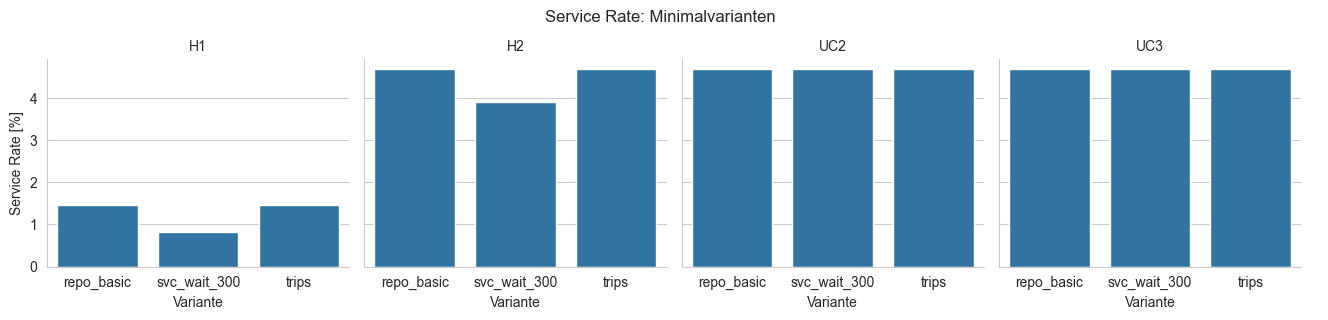

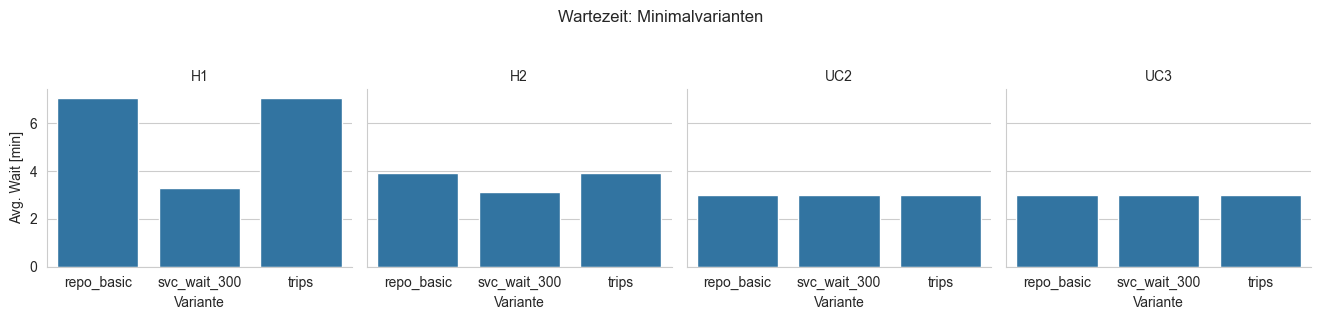

In [4]:
if not summary.empty:
    sns.set_style("whitegrid")

    g1 = sns.catplot(
        data=summary,
        x="variant",
        y="service_rate_pct",
        col="study",
        kind="bar",
        height=3,
        aspect=1.1,
    )
    g1.set_axis_labels("Variante", "Service Rate [%]")
    g1.set_titles("{col_name}")
    g1.fig.suptitle("Service Rate: Minimalvarianten", y=1.05)

    g2 = sns.catplot(
        data=summary,
        x="variant",
        y="avg_wait_min",
        col="study",
        kind="bar",
        height=3,
        aspect=1.1,
    )
    g2.set_axis_labels("Variante", "Avg. Wait [min]")
    g2.set_titles("{col_name}")
    g2.fig.suptitle("Wartezeit: Minimalvarianten", y=1.05)

    plt.tight_layout()
else:
    print("Keine Daten gefunden.")